In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box

# Buffer creation

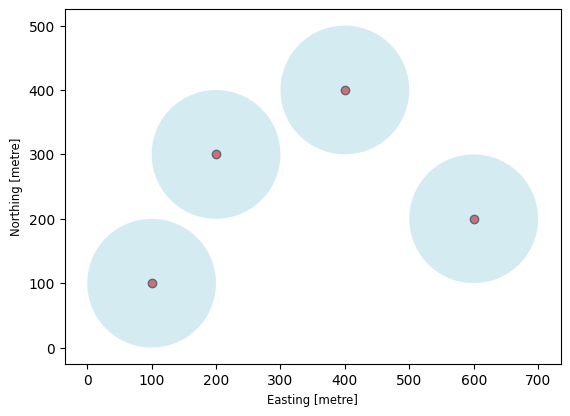

In [2]:
points = gpd.GeoDataFrame(
    geometry=[
        Point(100, 100),
        Point(200, 300),
        Point(400, 400),
        Point(600, 200)
    ],
    crs="EPSG:32643"
)

buffers = points.copy()
buffers["geometry"] = points.geometry.buffer(100)

ax = points.plot(color="red", edgecolor="black")
buffers.plot(ax=ax, color="lightblue", alpha=0.5)

plt.show()

# Overlay view

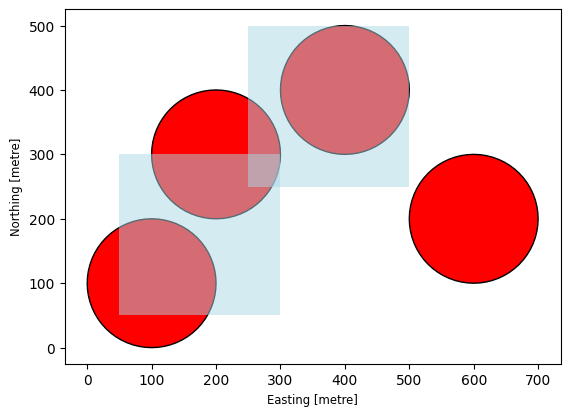

In [3]:
polygons = gpd.GeoDataFrame(
    geometry=[
        box(50, 50, 300, 300),
        box(250, 250, 500, 500)
    ],
    crs="EPSG:32643"
)

result = gpd.overlay(polygons, buffers, how="intersection")

ax = buffers.plot(color="red", edgecolor="black")
polygons.plot(ax=ax, color="lightblue", alpha=0.5)

plt.show()

# With the Given data

In [4]:
bp = r"/content/drive/MyDrive/MTech_Shape_files/nedumangad/buildings/nedumangad_buildings.shp"
roads = r"/content/drive/MyDrive/MTech_Shape_files/nedumangad/roads/nedumangad_road.shp"
water = r"/content/drive/MyDrive/MTech_Shape_files/nedumangad/waterways/nedumangad_waterways.shp"
pois = r"/content/drive/MyDrive/MTech_Shape_files/nedumangad/pois/nedumangad_pois.shp"
lulc = r"/content/drive/MyDrive/MTech_Shape_files/nedumangad/landuse/nedumangad_landuse.shp"

In [5]:
b = gpd.read_file(bp)
b.columns

Index(['fid', 'osm_id', 'code', 'fclass', 'name', 'type', 'geometry'], dtype='object')

In [6]:
r = gpd.read_file(roads)
r.columns

Index(['fid', 'osm_id', 'code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed',
       'layer', 'bridge', 'tunnel', 'geometry'],
      dtype='object')

In [7]:
w = gpd.read_file(water)
w.columns

Index(['fid', 'osm_id', 'code', 'fclass', 'width', 'name', 'geometry'], dtype='object')

In [8]:
p = gpd.read_file(pois)
p.columns

Index(['osm_id', 'code', 'fclass', 'name', 'geometry'], dtype='object')

In [9]:
l = gpd.read_file(lulc)
l.columns

Index(['osm_id', 'code', 'fclass', 'name', 'geometry'], dtype='object')

In [10]:
# CRS correction (preprocessing)
# Make sure to run this cell strictly once, if you run it multiple times bounds will be inf

b = b.set_crs("EPSG:4326", allow_override=True)   # rewrite the metadata
b = b.to_crs("EPSG:32643")                        # actually transform it

r = r.set_crs("EPSG:4326", allow_override=True)
r = r.to_crs("EPSG:32643")

w = w.set_crs("EPSG:4326", allow_override=True)
w = w.to_crs("EPSG:32643")

p = p.set_crs("EPSG:4326", allow_override=True)
p = p.to_crs("EPSG:32643")

l = l.set_crs("EPSG:4326", allow_override=True)
l = l.to_crs("EPSG:32643")

print(b.crs)
print(b.total_bounds)

print(w.crs)
print(w.total_bounds)

print(r.crs)
print(r.total_bounds)

print(p.crs)
print(p.total_bounds)

print(l.crs)
print(l.total_bounds)

EPSG:32643
[704003.58646088 939834.14877419 742030.83238092 977372.81694622]
EPSG:32643
[704241.87975757 939832.07635188 743696.1012696  977132.53209224]
EPSG:32643
[704035.02920147 939684.8188251  743735.57661122 977372.92306555]
EPSG:32643
[705026.92781164 939990.77603993 739916.55228779 977365.13194876]
EPSG:32643
[704751.63720743 939949.74427294 745233.30367806 977370.97675543]


# Buildings within 100m of streams

Total buildings:  31778
Buildings within 100m river:  922
Exposed share:  0.02901378312039776


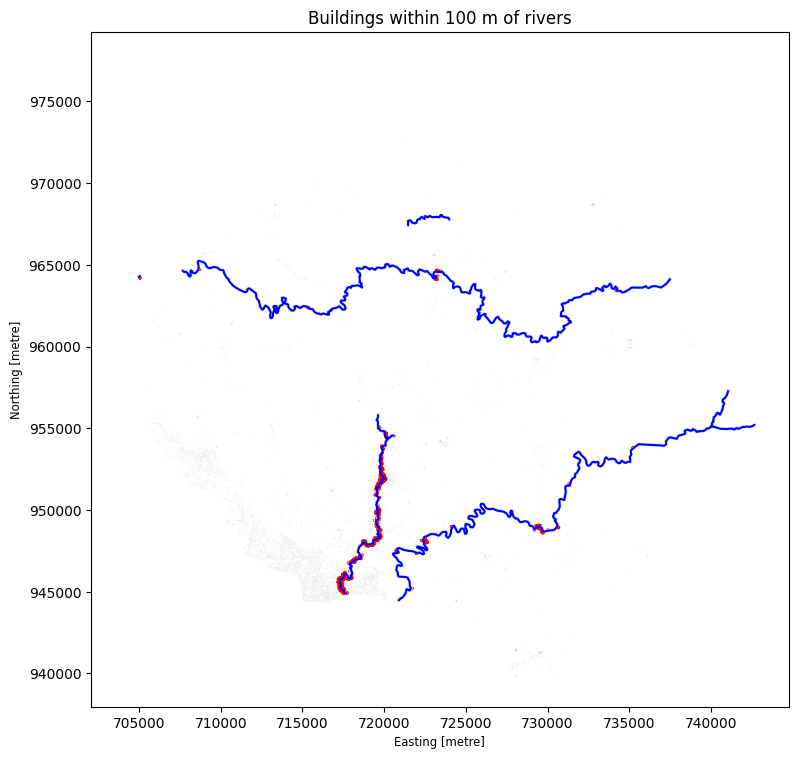

In [11]:
rivers =w[w["fclass"].isin(["river"])]
river_buffer =  gpd.GeoDataFrame(geometry=[rivers.buffer(100).union_all()],
                                 crs = "EPSG:32643")
e = gpd.sjoin(b,river_buffer,predicate="intersects",
              how="inner")

print("Total buildings: ",len(b))
print("Buildings within 100m river: ", len(e))
print("Exposed share: ", len(e)/len(b))

ax=river_buffer.plot(color="lightblue", alpha=0.5, figsize=(9, 9))
b.plot(ax=ax,color="lightgrey")
e.plot(ax=ax ,facecolor="red", edgecolor="red", linewidth=2)
rivers.plot(ax=ax,color="blue")
plt.title("Buildings within 100 m of rivers"); plt.show()

# Bridges on top of rivers

Total bridges on top of river:  52
Bridge names (any 10): 
 0                              MC Road
1                                 None
2          Vamanapuram Aramthanam Road
3                                 None
4                                 None
5                                 None
6                                 None
7    Kallara-Muthuvila-Nedumagadu Road
8         Nedumangad - Shorlacode Road
9                     koovakudi bridge
Name: name_2, dtype: object


/tmp/ipykernel_689/385250021.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


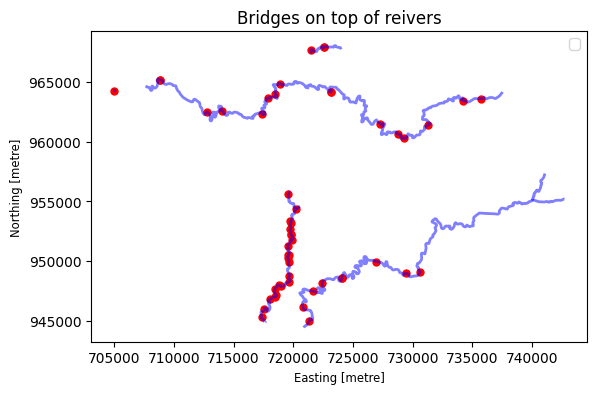

In [12]:
bridges = r[r["bridge"].isin(["T"])]
rivers = w[w["fclass"].isin(["river","canals"])]

e = gpd.overlay(rivers,bridges,how="intersection",keep_geom_type=False)

print("Total bridges on top of river: ", len(e))
print("Bridge names (any 10): \n", e["name_2"].head(10))

ax = rivers.plot(linewidth=2, alpha=0.5, color="blue")
e.plot(ax=ax, color="red",markersize=25)
plt.legend()
plt.title("Bridges on top of reivers")
plt.show()